In [3]:

import tensorflow as tf
from tensorflow.keras.datasets import fashion_mnist
import matplotlib.pyplot as plt
import seaborn as sns

# Pour la reproductibilité
tf.random.set_seed(42)

# Chargement du dataset
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()


29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [4]:
print("Train :", x_train.shape)
print("Test :", x_test.shape)

Train : (60000, 28, 28)
Test : (10000, 28, 28)


In [5]:

from tensorflow.keras.utils import to_categorical

# Normalisation des pixels entre 0 et 1
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# Encodage one-hot des labels
y_train_cat = to_categorical(y_train, 10)
y_test_cat = to_categorical(y_test, 10)


In [6]:

print("Type des images :", x_train.dtype)
print("Valeur minimale :", x_train.min())
print("Valeur maximale :", x_train.max())

print("Label original :", y_train[0])
print("Label encodé :", y_train_cat[0])

print("Dimensions x_train :", x_train.shape)
print("Dimensions y_train_cat :", y_train_cat.shape)


Type des images : float32
Valeur minimale : 0.0
Valeur maximale : 1.0
Label original : 9
Label encodé : [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
Dimensions x_train : (60000, 28, 28)
Dimensions y_train_cat : (60000, 10)


In [7]:

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Flatten, Dense, Dropout

model = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.2),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)


In [9]:

history = model.fit(
    x_train, y_train_cat,
    epochs=10,
    batch_size=128,
    validation_split=0.2
)


Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.7819 - loss: 0.6284 - val_accuracy: 0.8440 - val_loss: 0.4408
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8472 - loss: 0.4279 - val_accuracy: 0.8559 - val_loss: 0.3975
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8608 - loss: 0.3863 - val_accuracy: 0.8609 - val_loss: 0.3826
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8687 - loss: 0.3606 - val_accuracy: 0.8678 - val_loss: 0.3630
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8749 - loss: 0.3438 - val_accuracy: 0.8694 - val_loss: 0.3559
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8783 - loss: 0.3298 - val_accuracy: 0.8672 - val_loss: 0.3584
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8828 - loss: 0.3177 - val_accuracy: 0.8744 - val_loss: 0.3386
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8870 - loss: 0.3074 - val_accuracy: 0.

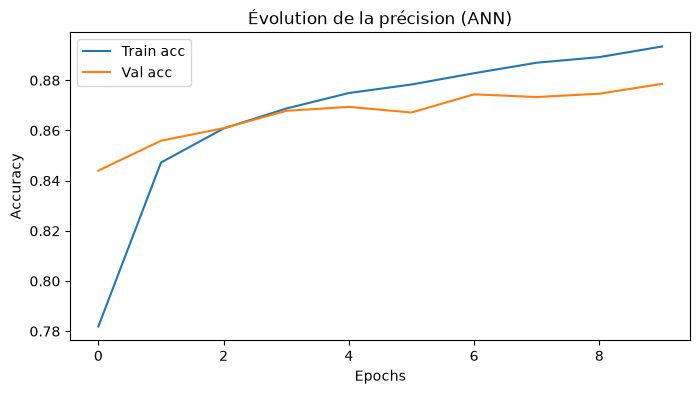

In [10]:

plt.figure(figsize=(8, 4))

plt.plot(history.history['accuracy'], label='Train acc')
plt.plot(history.history['val_accuracy'], label='Val acc')

plt.legend()
plt.title("Évolution de la précision (ANN)")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.show()


In [11]:

test_loss, test_acc = model.evaluate(x_test, y_test_cat)

print("Précision sur le test set :", test_acc)
print("Perte sur le test set :", test_loss)


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8685 - loss: 0.3603
Précision sur le test set : 0.8684999942779541
Perte sur le test set : 0.3603261113166809


In [12]:

from tensorflow.keras.layers import LeakyReLU

activations = ['sigmoid', 'tanh', 'relu']
results = {}

for act in activations:
    model_act = Sequential([
        Input(shape=(28, 28)),
        Flatten(),
        Dense(128, activation=act),
        Dense(64, activation=act),
        Dense(10, activation='softmax')
    ])

    model_act.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    model_act.fit(
        x_train, y_train_cat,
        epochs=5,
        batch_size=128,
        validation_split=0.2,
        verbose=0
    )

    _, acc = model_act.evaluate(
        x_test, y_test_cat, verbose=0
    )

    results[act] = acc

# Modèle avec LeakyReLU
model_leaky = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128),
    LeakyReLU(0.1),
    Dense(64),
    LeakyReLU(0.1),
    Dense(10, activation='softmax')
])

model_leaky.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model_leaky.fit(
    x_train, y_train_cat,
    epochs=5,
    batch_size=128,
    validation_split=0.2,
    verbose=0
)

_, acc = model_leaky.evaluate(
    x_test, y_test_cat, verbose=0
)

results['leaky_relu'] = acc

# Afficher les résultats
print("Comparaison des fonctions d'activation")
for act, acc in results.items():
    print(f"{act}: {acc:.4f}")


Comparaison des fonctions d'activation
sigmoid: 0.8584
tanh: 0.8615
relu: 0.8690
leaky_relu: 0.8662


In [ ]:

plt.figure(figsize=(8, 4))

plt.bar(results.keys(), results.values())

plt.title("Comparaison des fonctions d'activation")
plt.xlabel("Fonction d'activation")
plt.ylabel("Test Accuracy")
plt.ylim(0, 1)
plt.grid(axis='y', alpha=0.3)

plt.show()


In [13]:

# Ajouter la dimension du canal
x_train_cnn = x_train.reshape(-1, 28, 28, 1)
x_test_cnn = x_test.reshape(-1, 28, 28, 1)

print("Train CNN :", x_train_cnn.shape)
print("Test CNN :", x_test_cnn.shape)


Train CNN : (60000, 28, 28, 1)
Test CNN : (10000, 28, 28, 1)


In [14]:

from tensorflow.keras.layers import Conv2D, MaxPooling2D

model_cnn = Sequential([
    Input(shape=(28, 28, 1)),

    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Flatten(),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

model_cnn.summary()


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:

model_cnn.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)


In [16]:

history_cnn = model_cnn.fit(
    x_train_cnn,
    y_train_cat,
    epochs=5,
    batch_size=128,
    validation_split=0.2
)


Epoch 1/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.7774 - loss: 0.6197 - val_accuracy: 0.8549 - val_loss: 0.4201
Epoch 2/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.8631 - loss: 0.3826 - val_accuracy: 0.8720 - val_loss: 0.3637
Epoch 3/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.8800 - loss: 0.3371 - val_accuracy: 0.8800 - val_loss: 0.3362
Epoch 4/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.8894 - loss: 0.3076 - val_accuracy: 0.8838 - val_loss: 0.3205
Epoch 5/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.8976 - loss: 0.2851 - val_accuracy: 0.8870 - val_loss: 0.3076


In [17]:

# Évaluer le CNN
test_loss_cnn, test_acc_cnn = model_cnn.evaluate(
    x_test_cnn, y_test_cat
)

# Comparer les résultats
print(f"Accuracy ANN : {test_acc * 100:.2f}%")
print(f"Accuracy CNN : {test_acc_cnn * 100:.2f}%")

print(f"Loss ANN : {test_loss:.4f}")
print(f"Loss CNN : {test_loss_cnn:.4f}")


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8846 - loss: 0.3213
Accuracy ANN : 86.85%
Accuracy CNN : 88.46%
Loss ANN : 0.3603
Loss CNN : 0.3213


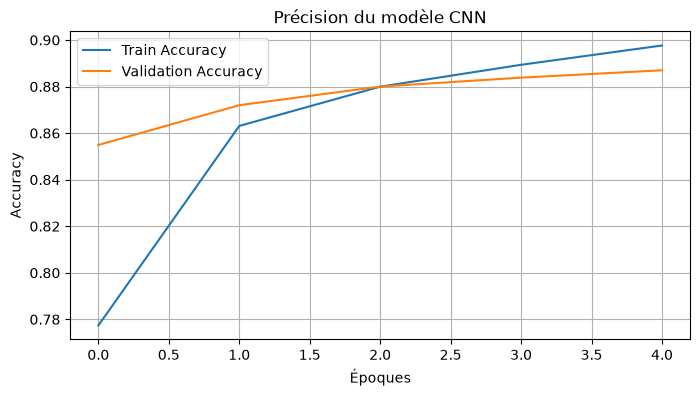

In [18]:

plt.figure(figsize=(8, 4))

plt.plot(history_cnn.history['accuracy'],
         label='Train Accuracy')

plt.plot(history_cnn.history['val_accuracy'],
         label='Validation Accuracy')

plt.title("Précision du modèle CNN")
plt.xlabel("Époques")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.show()


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


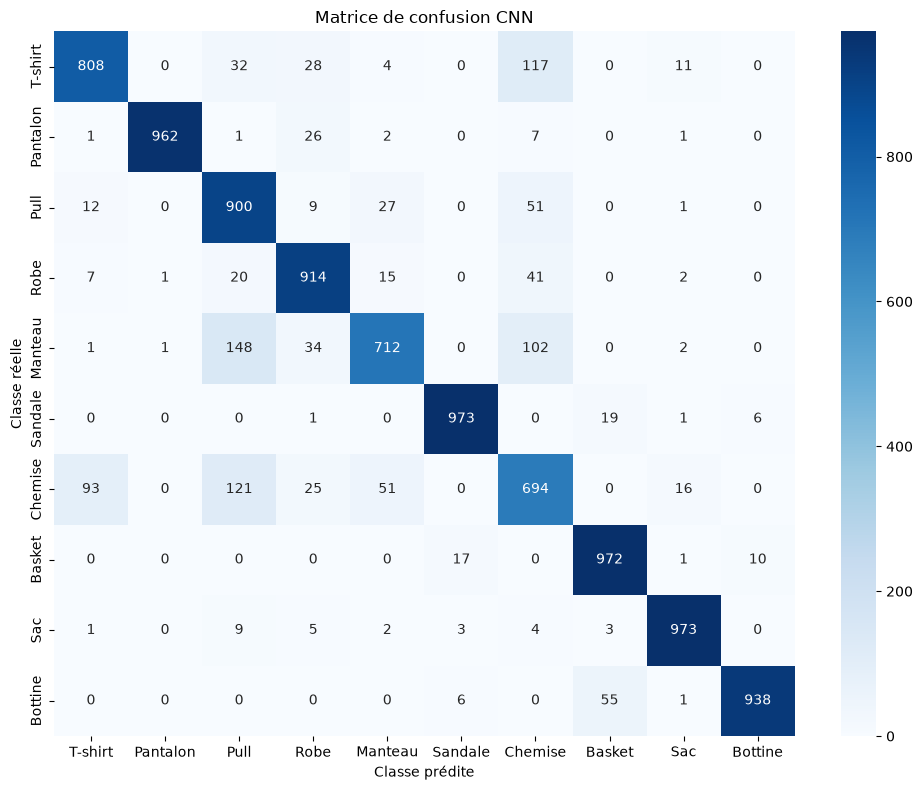

In [19]:

import numpy as np
from sklearn.metrics import confusion_matrix

# Prédictions du CNN
predictions = model_cnn.predict(x_test_cnn)

# Conversion des probabilités en classes
y_pred = np.argmax(predictions, axis=1)

# Calcul de la matrice de confusion
cm = confusion_matrix(y_test, y_pred)

class_names = [
    "T-shirt", "Pantalon", "Pull", "Robe",
    "Manteau", "Sandale", "Chemise",
    "Basket", "Sac", "Bottine"
]

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Classe prédite")
plt.ylabel("Classe réelle")
plt.title("Matrice de confusion CNN")

plt.tight_layout()
plt.show()


In [20]:

# Ne pas considérer la diagonale (prédictions correctes)
cm_errors = cm.copy()
np.fill_diagonal(cm_errors, 0)

# Trouver la confusion la plus fréquente
i, j = np.unravel_index(
    np.argmax(cm_errors),
    cm_errors.shape
)

print("Classe réelle :", class_names[i])
print("Classe prédite :", class_names[j])
print("Nombre d'erreurs :", cm_errors[i, j])


Classe réelle : Manteau
Classe prédite : Pull
Nombre d'erreurs : 148


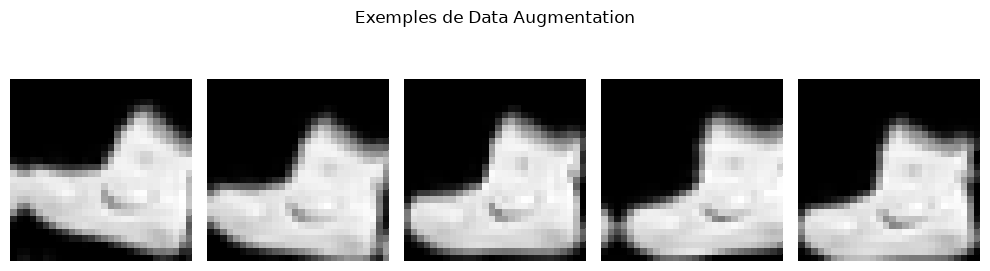

In [21]:

from tensorflow.keras.layers import RandomRotation, RandomTranslation

data_augmentation = Sequential([
    RandomRotation(0.05),
    RandomTranslation(0.1, 0.1)
])

# Sélectionner une image
image = x_train_cnn[0:1]

plt.figure(figsize=(10, 3))

for i in range(5):
    augmented = data_augmentation(image, training=True)

    plt.subplot(1, 5, i + 1)
    plt.imshow(augmented[0, :, :, 0], cmap='gray')
    plt.axis('off')

plt.suptitle("Exemples de Data Augmentation")
plt.tight_layout()
plt.show()
